In [32]:
import numpy as np
import matplotlib.pyplot as plt

In [33]:
# Define a grid in the complex plane
x = np.linspace(-3, 3, 400)    # Real part
y = np.linspace(-3, 3, 400)    # Imaginary part
X, Y = np.meshgrid(x, y)
Z = X + 1j * Y    # Complex plane grid

In [34]:
# Stability functions R(h$lambda$) for different methods
def euler_stability(Z):
  return 1 + Z    # Forward Euler: R(h$lambda$) = 1+h(h$lambda$)

In [35]:
def modified_euler_stability(Z):
  return 1 + Z + (Z**2)/2    # Improved Euler (Heun's Method)

In [36]:
def rk4_stability(Z):
  return 1 + Z + (Z**2)/2 + (Z**3)/6 + (Z**4)/24    # RK4 stability function

In [37]:
def backward_euler_stability(Z):
  return 1 / (1-Z)    # Backward Euler: R(h$lambda$) = 1/(1-h$lambda$)

In [38]:
# Compute absolute stability regions
stability_euler = np.abs(euler_stability(Z)) <= 1
stability_modified_euler = np.abs(modified_euler_stability(Z)) <= 1
stability_rk4 = np.abs(rk4_stability(Z)) <= 1
# stability_backward_euler = np.abs(backward_euler_stability(Z)) <= 1

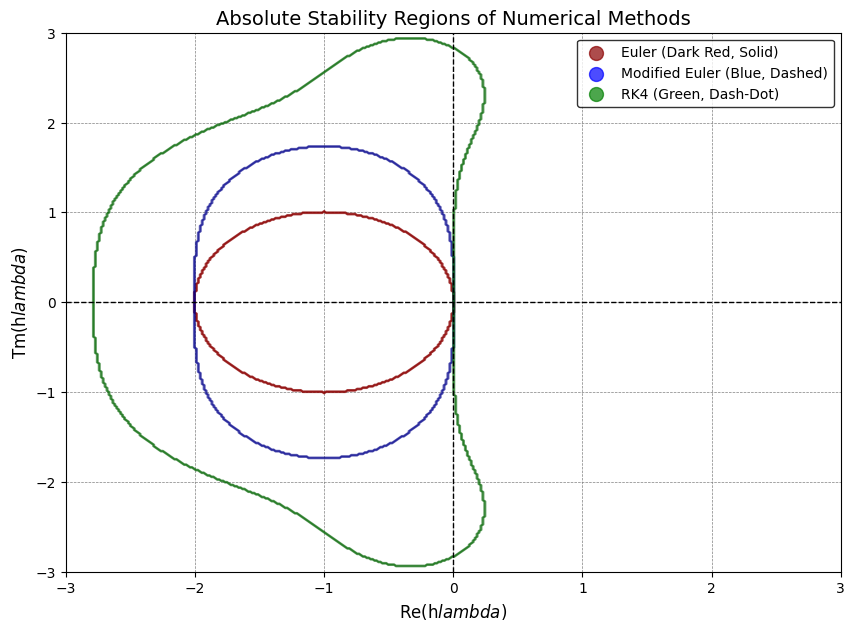

In [39]:
# Plotting
plt.figure(figsize=(10, 7), facecolor='white')    # Set white background
# Euler Method Stability Region (Light Red)
plt.contour(X, Y, stability_euler, levels=1, colors=['#8B0000'], alpha=0.7)
# Modified Euler Method Stability Region (Light Blue)
plt.contour(X, Y, stability_modified_euler, levels=1, colors=['#00008B'], alpha=0.6)
# Rk4 Stability Region (Light Green)
plt.contour(X, Y, stability_rk4, levels=1, colors=['#006400'], alpha=0.6)
# Backward Euler Stability Region (Light Purple)
# plt.contour(X, Y, stability_backward_euler, levels=1, colors=['#cc99ff'], alpha=0.5)
# Labels and title
plt.axhline(0, color='black', linewidth=1, linestyle='--')
plt.axvline(0, color='black', linewidth=1, linestyle='--')
plt.xlabel('Re(h$lambda$)', fontsize=12)
plt.ylabel('Tm(h$lambda$)', fontsize=12)
plt.title("Absolute Stability Regions of Numerical Methods", fontsize=14)
plt.grid(True, linestyle='--', linewidth=0.5, color='gray')
# Custom legend using scatter (since contourf doesn't support labels)
legend_labels = ['Euler (Dark Red, Solid)', 'Modified Euler (Blue, Dashed)', 'RK4 (Green, Dash-Dot)']
legend_colors = ['#8B0000', 'blue', 'green']
line_styles = ['solid', 'dashed', 'dashdot']
for i, label in enumerate(legend_labels):
  plt.scatter([], [], color=legend_colors[i], label=label, alpha=0.7, s=100)
plt.legend(fontsize=10, loc='upper right', frameon=True, edgecolor='black')
plt.show()